In [1]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 2. Data loading setup (Replace path with your own file if needed)
# Example: df = pd.read_csv('your_dataset.csv')

print("Successfully imported libraries for the Linear Regression modeling pipeline!")

Successfully imported libraries for the Linear Regression modeling pipeline!


In [2]:
import os
import pandas as pd

def load_dataset(name: str, path: str) -> pd.DataFrame:
    """Load dataset from a CSV file, verify file existence, and print basic shape information."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"Error: Could not find {name} file at path: {path}")
    
    df = pd.read_csv(path)
    print(f"-> Loaded {name}: {df.shape[0]} rows, {df.shape[1]} columns.")
    return df

# 1. Define paths to the Train, Validation, and Test splits
train_path = r"D:\File Code\Smartphone Price Prediction\data\smartphones_train_clean.csv"
val_path = r"D:\File Code\Smartphone Price Prediction\data\smartphones_val_clean.csv"
test_path = r"D:\File Code\Smartphone Price Prediction\data\smartphones_test_clean.csv"

# 2. Load the datasets
df_train = load_dataset("TRAIN", train_path)
df_val = load_dataset("VALIDATION", val_path)
df_test = load_dataset("TEST", test_path)

print("\n--- SUCCESSFULLY LOADED ALL 3 DATASETS ---")
print(f"Train Set: {df_train.shape}")
print(f"Val Set:   {df_val.shape}")
print(f"Test Set:  {df_test.shape}")

-> Loaded TRAIN: 1337 rows, 21 columns.
-> Loaded VALIDATION: 286 rows, 21 columns.
-> Loaded TEST: 287 rows, 21 columns.

--- SUCCESSFULLY LOADED ALL 3 DATASETS ---
Train Set: (1337, 21)
Val Set:   (286, 21)
Test Set:  (287, 21)


In [3]:
# Inspect overall column structure, data types, and non-null counts
print("--- DATASET STRUCTURE INFORMATION ---")
df_train.info()

# Check missing value (NaN) counts per column
print("\n--- MISSING VALUE (NaN) COUNTS PER COLUMN ---")
print(df_train.isnull().sum())

# Descriptive statistics for numeric columns
print("\n--- DESCRIPTIVE STATISTICS FOR NUMERIC COLUMNS ---")
display(df_train.describe())

--- DATASET STRUCTURE INFORMATION ---
<class 'pandas.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Brand                         1337 non-null   str    
 1   Price (EUR)                   1337 non-null   float64
 2   RAM (GB)                      1337 non-null   float64
 3   ROM (GB)                      1337 non-null   float64
 4   Screen Size (inch)            1337 non-null   float64
 5   Screen-to-Body Ratio (%)      1337 non-null   float64
 6   Display Panel                 1337 non-null   str    
 7   Rear Camera (MP)              1337 non-null   float64
 8   Front Camera (MP)             1337 non-null   float64
 9   Battery Capacity (mAh)        1337 non-null   float64
 10  Battery Design                1337 non-null   str    
 11  Thickness (mm)                1337 non-null   float64
 12  Weight (g)                    1337 

,Price (EUR),RAM (GB),ROM (GB),Screen Size (inch),Screen-to-Body Ratio (%),Rear Camera (MP),Front Camera (MP),Battery Capacity (mAh),Thickness (mm),Weight (g),CPU Cores,CPU Clock Speed (GHz),Release Year,NFC_Clean,Diagonal Resolution (Pixels)
count,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000
mean,232.513089,1.847607,22.184667,5.051137,66.565744,9.998803,3.818025,2565.137622,9.073972,157.493418,4.627524,1.486761,2014.270007,0.317128,1573.043769
std,136.967138,1.017488,26.405151,0.762333,6.289098,4.443367,3.352262,790.884127,1.709163,42.176233,2.259131,0.389513,1.634565,0.465532,567.670958
min,40.000000,1.000000,1.000000,3.000000,22.800000,0.300000,0.000000,1000.000000,4.900000,88.200000,1.000000,0.400000,2007.000000,0.000000,400.000000
25%,140.000000,1.000000,8.000000,4.650000,64.200000,8.000000,1.300000,2000.000000,8.000000,138.900000,4.000000,1.200000,2013.000000,0.000000,1101.453585
50%,200.000000,1.750000,16.000000,5.000000,67.500000,8.000000,2.100000,2470.000000,8.900000,149.000000,4.000000,1.400000,2014.000000,0.000000,1468.604780
75%,280.000000,2.000000,32.000000,5.500000,70.600000,13.000000,5.000000,3000.000000,9.800000,164.000000,8.000000,1.700000,2015.000000,1.000000,2202.907170
max,1400.000000,8.000000,256.000000,8.000000,93.200000,41.000000,20.000000,7000.000000,21.100000,480.000000,10.000000,2.700000,2017.000000,1.000000,4405.814340


In [4]:
import pandas as pd

# Identify target column and categorical features
target_col = 'Price (EUR)'
object_cols = df_train.select_dtypes(include=['object']).columns.tolist()

print(f"Categorical variables for One-Hot Encoding: {object_cols}")

# Preserve consistent category ordering for Chip Brand across splits
chip_order = ['Apple', 'Exynos', 'Intel', 'Other', 'Kirin', 'MediaTek', 'Snapdragon', 'Spreadtrum']
for _df in (df_train, df_val, df_test):
    _df['Chip Brand'] = pd.Categorical(_df['Chip Brand'], categories=chip_order)

# Separate features (X) and target variable (y) before One-Hot Encoding
y_train = df_train[target_col]
y_val = df_val[target_col]
y_test = df_test[target_col]

X_train_raw = df_train.drop(columns=[target_col])
X_val_raw = df_val.drop(columns=[target_col])
X_test_raw = df_test.drop(columns=[target_col])

# Apply pd.get_dummies
X_train_encoded = pd.get_dummies(X_train_raw, columns=object_cols, drop_first=True)
X_val_encoded = pd.get_dummies(X_val_raw, columns=object_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_raw, columns=object_cols, drop_first=True)

# Synchronize column structures across splits so the model receives a consistent input format
X_train, X_val = X_train_encoded.align(X_val_encoded, join='left', axis=1, fill_value=0)
X_train, X_test = X_train.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Convert boolean dummy columns to float (0.0 / 1.0)
X_train = X_train.astype(float)
X_val = X_val.astype(float)
X_test = X_test.astype(float)

print("\n--- SHAPE INFORMATION AFTER ONE-HOT ENCODING ---")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")

Categorical variables for One-Hot Encoding: ['Brand', 'Display Panel', 'Battery Design', 'Fingerprint Sensor', 'Network Support', 'Chip Brand']

--- SHAPE INFORMATION AFTER ONE-HOT ENCODING ---
X_train shape: (1337, 90)
X_val shape:   (286, 90)
X_test shape:  (287, 90)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17048\3754987908.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df_train.select_dtypes(include=['object']).columns.tolist()


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Initialize and train the Baseline Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on the Train and Validation sets
y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)

# Evaluate model performance
def evaluate_predictions(y_true, y_pred, dataset_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"=== EVALUATION RESULTS ON {dataset_name.upper()} SET ===")
    print(f"MAE : {mae:.4f} EUR")
    print(f"RMSE: {rmse:.4f} EUR")
    print(f"R²  : {r2:.4f}\n")

evaluate_predictions(y_train, y_train_pred, "Train")
evaluate_predictions(y_val, y_val_pred, "Validation")

=== EVALUATION RESULTS ON TRAIN SET ===
MAE : 48.2245 EUR
RMSE: 71.1959 EUR
R²  : 0.7296

=== EVALUATION RESULTS ON VALIDATION SET ===
MAE : 58.1961 EUR
RMSE: 86.2328 EUR
R²  : 0.6154



### 1. Creating Physical and Technical Performance Features
To help machine learning models (especially linear models) capture complex non-linear interactions in the real world, we combine individual hardware specifications into composite indices with concrete physical and economic meaning:
* **Pixel Density (`PPI`)**: Measures actual display sharpness from diagonal pixel resolution and physical screen size rather than relying on inches alone.
* **Battery Engineering Optimization (`Battery/Thickness Ratio`)**: Reflects internal manufacturing sophistication and device tier (packing a large battery into a slim chassis).
* **Raw Processing Capacity (`Total CPU Clock`)**: Approximates maximum theoretical CPU throughput by multiplying the number of CPU cores by single-core clock speed.
* **Overall Performance Index (`Performance Index`)**: Combines physical RAM capacity with total CPU clock speed to estimate real-world multitasking capability.
* **Total Camera Megapixels (`Total Camera MP`)**: Sums rear and front camera megapixels to represent overall investment in imaging hardware.

In [6]:
def create_engineered_features(df):
    # Create a copy to avoid modifying the original DataFrame in place
    df_feat = df.copy()

    # 1. Pixel Density (PPI)
    df_feat['PPI'] = df_feat['Diagonal Resolution (Pixels)'] / df_feat['Screen Size (inch)']

    # 2. Battery design optimization (Battery/Thickness Ratio)
    df_feat['Battery/Thickness Ratio'] = df_feat['Battery Capacity (mAh)'] / df_feat['Thickness (mm)']

    # 3. Raw processing capacity (Total CPU Clock)
    df_feat['Total CPU Clock'] = df_feat['CPU Cores'] * df_feat['CPU Clock Speed (GHz)']

    # 4. Overall performance index
    df_feat['Performance Index'] = df_feat['RAM (GB)'] * df_feat['Total CPU Clock']

    # 5. Total camera resolution
    df_feat['Total Camera MP'] = df_feat['Rear Camera (MP)'] + df_feat['Front Camera (MP)']

    return df_feat

# Apply feature creation across all 3 data splits
df_train_feat = create_engineered_features(df_train)
df_val_feat = create_engineered_features(df_val)
df_test_feat = create_engineered_features(df_test)

print("--- SUCCESSFULLY ADDED 5 NEW ENGINEERED FEATURES ---")
display(df_train_feat[['PPI', 'Battery/Thickness Ratio', 'Total CPU Clock', 'Performance Index', 'Total Camera MP']].head())

--- SUCCESSFULLY ADDED 5 NEW ENGINEERED FEATURES ---


,PPI,Battery/Thickness Ratio,Total CPU Clock,Performance Index,Total Camera MP
0,489.534927,364.583333,16.0,48.0,32.0
1,293.720956,275.000000,5.0,10.0,18.0
2,283.019434,329.333333,9.2,18.4,6.2
3,440.581434,285.714286,9.2,18.4,15.0
4,293.720956,518.987342,11.2,33.6,18.0


In [7]:
# Separate new feature matrices (X) and target vectors (y)
y_train_f = df_train_feat[target_col]
y_val_f = df_val_feat[target_col]
y_test_f = df_test_feat[target_col]

X_train_raw_f = df_train_feat.drop(columns=[target_col])
X_val_raw_f = df_val_feat.drop(columns=[target_col])
X_test_raw_f = df_test_feat.drop(columns=[target_col])

# Perform One-Hot Encoding on the dataset containing the new features
X_train_encoded_f = pd.get_dummies(X_train_raw_f, columns=object_cols, drop_first=True)
X_val_encoded_f = pd.get_dummies(X_val_raw_f, columns=object_cols, drop_first=True)
X_test_encoded_f = pd.get_dummies(X_test_raw_f, columns=object_cols, drop_first=True)

# Synchronize column structures across all splits
X_train_f, X_val_f = X_train_encoded_f.align(X_val_encoded_f, join='left', axis=1, fill_value=0)
X_train_f, X_test_f = X_train_f.align(X_test_encoded_f, join='left', axis=1, fill_value=0)

# Cast columns to float
X_train_f = X_train_f.astype(float)
X_val_f = X_val_f.astype(float)
X_test_f = X_test_f.astype(float)

print(f"New training set shape: {X_train_f.shape}")

New training set shape: (1337, 95)


In [8]:
# Retrain the Linear Regression model with the newly added physical features
lr_model_f = LinearRegression()
lr_model_f.fit(X_train_f, y_train_f)

# Predict
y_train_pred_f = lr_model_f.predict(X_train_f)
y_val_pred_f = lr_model_f.predict(X_val_f)

# Evaluate
print("=== RESULTS WITH NEW PHYSICAL & PERFORMANCE FEATURES ===")
evaluate_predictions(y_train_f, y_train_pred_f, "Train (New)")
evaluate_predictions(y_val_f, y_val_pred_f, "Validation (New)")

=== RESULTS WITH NEW PHYSICAL & PERFORMANCE FEATURES ===
=== EVALUATION RESULTS ON TRAIN (NEW) SET ===
MAE : 47.5849 EUR
RMSE: 69.1382 EUR
R²  : 0.7450

=== EVALUATION RESULTS ON VALIDATION (NEW) SET ===
MAE : 56.7385 EUR
RMSE: 83.9240 EUR
R²  : 0.6357



### 2. Time-Relative Feature Normalization (Moore's Law)
The smartphone dataset spans from 2007 to 2017, a decade in which semiconductor technology and mobile hardware advanced exponentially according to Moore's Law. A hardware configuration that was an ultra-expensive flagship in 2011 (such as 1 GB of RAM) became an entry-level budget configuration by 2016.

To enable the model to recognize a device's market positioning **at the exact time of its release**, we apply the following technique:
1. Compute the yearly average hardware specifications (`RAM (GB)`, `ROM (GB)`, `Total Camera MP`) strictly from the historical **Train Set** (preventing any data leakage from Validation/Test).
2. Create relative ratio features: `RAM_Rel_Year`, `ROM_Rel_Year`, and `Cam_Rel_Year` by dividing each device's actual specification by the average specification of its release year.

As a result, a phone with significantly higher RAM than the average of its release year will be accurately identified as a high-end flagship regardless of the era.

In [9]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# --- PREPARE INDEPENDENT TIME-RELATIVE FEATURES (USING ORIGINAL DATA ONLY) ---
# Create a temporary column for 'Total Camera MP' on df_train to compute Moore's Law statistics
temp_train = df_train.copy()
temp_train['Total Camera MP'] = temp_train['Rear Camera (MP)'] + temp_train['Front Camera (MP)']

# 1. Compute yearly averages strictly from the original Train set
year_stats = temp_train.groupby('Release Year').agg(
    mean_ram=('RAM (GB)', 'mean'),
    mean_rom=('ROM (GB)', 'mean'),
    mean_cam=('Total Camera MP', 'mean')
).reset_index()

# Fallback global means from Train
global_ram_mean = df_train['RAM (GB)'].mean()
global_rom_mean = df_train['ROM (GB)'].mean()
global_cam_mean = temp_train['Total Camera MP'].mean()

def add_relative_features_only(df_raw, stats):
    df_feat = df_raw.copy()
    # Create temporary helper column for ratio calculation
    df_feat['Total Camera MP'] = df_feat['Rear Camera (MP)'] + df_feat['Front Camera (MP)']

    # Merge yearly average statistics
    df_merged = df_feat.merge(stats, on='Release Year', how='left')

    # Fill any unseen years with global training means
    df_merged['mean_ram'] = df_merged['mean_ram'].fillna(global_ram_mean)
    df_merged['mean_rom'] = df_merged['mean_rom'].fillna(global_rom_mean)
    df_merged['mean_cam'] = df_merged['mean_cam'].fillna(global_cam_mean)

    # Create the 3 Moore's Law time-relative features
    df_merged['RAM_Rel_Year'] = df_merged['RAM (GB)'] / df_merged['mean_ram']
    df_merged['ROM_Rel_Year'] = df_merged['ROM (GB)'] / df_merged['mean_rom']
    df_merged['Cam_Rel_Year'] = df_merged['Total Camera MP'] / df_merged['mean_cam']

    # Drop temporary helper and mean columns to keep this feature set completely independent
    df_merged = df_merged.drop(columns=['mean_ram', 'mean_rom', 'mean_cam', 'Total Camera MP'])
    return df_merged

# 2. Build datasets containing only the Moore's Law features (without the physical features from Part 1)
df_train_rel = add_relative_features_only(df_train, year_stats)
df_val_rel = add_relative_features_only(df_val, year_stats)
df_test_rel = add_relative_features_only(df_test, year_stats)

# 3. Separate input features and target labels
y_train_r = df_train_rel[target_col]
y_val_r = df_val_rel[target_col]
y_test_r = df_test_rel[target_col]

X_train_raw_r = df_train_rel.drop(columns=[target_col])
X_val_raw_r = df_val_rel.drop(columns=[target_col])
X_test_raw_r = df_test_rel.drop(columns=[target_col])

# 4. One-Hot Encode & align columns
X_train_encoded_r = pd.get_dummies(X_train_raw_r, columns=object_cols, drop_first=True)
X_val_encoded_r = pd.get_dummies(X_val_raw_r, columns=object_cols, drop_first=True)
X_test_encoded_r = pd.get_dummies(X_test_raw_r, columns=object_cols, drop_first=True)

X_train_r = X_train_encoded_r.astype(float)
X_val_r = X_val_encoded_r.reindex(columns=X_train_r.columns, fill_value=0).astype(float)
X_test_r = X_test_encoded_r.reindex(columns=X_train_r.columns, fill_value=0).astype(float)

# 5. Train Linear Regression model
lr_model_r = LinearRegression()
lr_model_r.fit(X_train_r, y_train_r)

y_train_pred_r = lr_model_r.predict(X_train_r)
y_val_pred_r = lr_model_r.predict(X_val_r)

print("=== INDEPENDENT MODEL RESULTS: USING MOORE'S LAW FEATURES ONLY ===")
evaluate_predictions(y_train_r, y_train_pred_r, "Train (Time Features Only)")
evaluate_predictions(y_val_r, y_val_pred_r, "Validation (Time Features Only)")

=== INDEPENDENT MODEL RESULTS: USING MOORE'S LAW FEATURES ONLY ===


=== EVALUATION RESULTS ON TRAIN (TIME FEATURES ONLY) SET ===
MAE : 47.3858 EUR
RMSE: 70.1169 EUR
R²  : 0.7377

=== EVALUATION RESULTS ON VALIDATION (TIME FEATURES ONLY) SET ===
MAE : 59.5717 EUR
RMSE: 93.8822 EUR
R²  : 0.5441



### 3. Evaluating the Combined Model with Both Feature Engineering Methods

We now generate both the physical/performance features and the time-relative (Moore's Law) features simultaneously on top of the original dataset to observe how their combination affects prediction accuracy.

In [10]:
# 1. Function to create the fully combined feature set consistently
def create_fully_combined_features(df_raw, stats):
    df_feat = df_raw.copy()

    # Create physical & performance features from Part 1
    df_feat['PPI'] = df_feat['Diagonal Resolution (Pixels)'] / df_feat['Screen Size (inch)']
    df_feat['Battery/Thickness Ratio'] = df_feat['Battery Capacity (mAh)'] / df_feat['Thickness (mm)']
    df_feat['Total CPU Clock'] = df_feat['CPU Cores'] * df_feat['CPU Clock Speed (GHz)']
    df_feat['Performance Index'] = df_feat['RAM (GB)'] * df_feat['Total CPU Clock']
    df_feat['Total Camera MP'] = df_feat['Rear Camera (MP)'] + df_feat['Front Camera (MP)']

    # Merge yearly average statistics from Train
    df_merged = df_feat.merge(stats, on='Release Year', how='left')

    # Handle fallback missing values
    df_merged['mean_ram'] = df_merged['mean_ram'].fillna(global_ram_mean)
    df_merged['mean_rom'] = df_merged['mean_rom'].fillna(global_rom_mean)
    df_merged['mean_cam'] = df_merged['mean_cam'].fillna(global_cam_mean)

    # Create Moore's Law time-relative features from Part 2
    df_merged['RAM_Rel_Year'] = df_merged['RAM (GB)'] / df_merged['mean_ram']
    df_merged['ROM_Rel_Year'] = df_merged['ROM (GB)'] / df_merged['mean_rom']
    df_merged['Cam_Rel_Year'] = df_merged['Total Camera MP'] / df_merged['mean_cam']

    # Drop temporary mean columns to keep the DataFrame clean
    df_merged = df_merged.drop(columns=['mean_ram', 'mean_rom', 'mean_cam'])
    return df_merged

# 2. Apply combined feature engineering across all 3 splits
df_train_comb = create_fully_combined_features(df_train, year_stats)
df_val_comb = create_fully_combined_features(df_val, year_stats)
df_test_comb = create_fully_combined_features(df_test, year_stats)

# 3. Separate independent variables X and target variable y
y_train_comb = df_train_comb[target_col]
y_val_comb = df_val_comb[target_col]
y_test_comb = df_test_comb[target_col]

X_train_raw_comb = df_train_comb.drop(columns=[target_col])
X_val_raw_comb = df_val_comb.drop(columns=[target_col])
X_test_raw_comb = df_test_comb.drop(columns=[target_col])

# 4. One-Hot Encode & synchronize columns
X_train_encoded_comb = pd.get_dummies(X_train_raw_comb, columns=object_cols, drop_first=True)
X_val_encoded_comb = pd.get_dummies(X_val_raw_comb, columns=object_cols, drop_first=True)
X_test_encoded_comb = pd.get_dummies(X_test_raw_comb, columns=object_cols, drop_first=True)

X_train_comb_final = X_train_encoded_comb.astype(float)
X_val_comb_final = X_val_encoded_comb.reindex(columns=X_train_comb_final.columns, fill_value=0).astype(float)
X_test_comb_final = X_test_encoded_comb.reindex(columns=X_train_comb_final.columns, fill_value=0).astype(float)

print(f"Training set shape with all combined features: {X_train_comb_final.shape}")

Training set shape with all combined features: (1337, 98)


In [11]:
# 5. Train and evaluate ordinary Linear Regression on the Combined dataset
lr_model_comb = LinearRegression()
lr_model_comb.fit(X_train_comb_final, y_train_comb)

y_train_pred_comb = lr_model_comb.predict(X_train_comb_final)
y_val_pred_comb = lr_model_comb.predict(X_val_comb_final)

print("=== MODEL RESULTS WITH ALL COMBINED FEATURES (PHYSICAL + TIME-RELATIVE) ===")
evaluate_predictions(y_train_comb, y_train_pred_comb, "Train (Combined)")
evaluate_predictions(y_val_comb, y_val_pred_comb, "Validation (Combined)")

=== MODEL RESULTS WITH ALL COMBINED FEATURES (PHYSICAL + TIME-RELATIVE) ===


=== EVALUATION RESULTS ON TRAIN (COMBINED) SET ===
MAE : 46.6527 EUR
RMSE: 68.3022 EUR
R²  : 0.7511

=== EVALUATION RESULTS ON VALIDATION (COMBINED) SET ===
MAE : 58.0046 EUR
RMSE: 91.0453 EUR
R²  : 0.5712



### 4. Applying Log Transformation and Feature Scaling to the Combined Model
We simultaneously perform:
* Logarithmic transformation (`np.log1p`) on the right-skewed `ROM (GB)` feature and the target variable `Price (EUR)`.
* Feature standardization across all continuous numeric variables using `StandardScaler` (fitted strictly on the Train set, then transformed on Validation and Test) to eliminate scale disparities.

In [12]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Create copies from the fully combined feature sets
X_train_scaled = X_train_comb_final.copy()
X_val_scaled = X_val_comb_final.copy()
X_test_scaled = X_test_comb_final.copy()

# 2. Apply Log Transformation to the skewed feature (ROM)
if 'ROM (GB)' in X_train_scaled.columns:
    X_train_scaled['ROM (GB)'] = np.log1p(X_train_scaled['ROM (GB)'])
    X_val_scaled['ROM (GB)'] = np.log1p(X_val_scaled['ROM (GB)'])
    X_test_scaled['ROM (GB)'] = np.log1p(X_test_scaled['ROM (GB)'])

# Apply logarithmic transformation to the target variable
y_train_log = np.log1p(y_train_comb)
y_val_log = np.log1p(y_val_comb)
y_test_log = np.log1p(y_test_comb)

# 3. Standardize scales (StandardScaler) across all continuous numeric features
numeric_cols = [
    'RAM (GB)', 'ROM (GB)', 'Screen Size (inch)', 'Screen-to-Body Ratio (%)',
    'Rear Camera (MP)', 'Front Camera (MP)', 'Battery Capacity (mAh)', 'Thickness (mm)',
    'Weight (g)', 'CPU Cores', 'CPU Clock Speed (GHz)', 'Release Year',
    'Diagonal Resolution (Pixels)', 'PPI', 'Battery/Thickness Ratio', 'Total CPU Clock',
    'Performance Index', 'Total Camera MP', 'RAM_Rel_Year', 'ROM_Rel_Year', 'Cam_Rel_Year'
]

# Filter for numeric columns actually present in the dataset
numeric_cols = [col for col in numeric_cols if col in X_train_scaled.columns]

scaler = StandardScaler()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
X_val_scaled[numeric_cols] = scaler.transform(X_val_scaled[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

print("Completed Log Transformation (ROM & Target) and feature standardization with StandardScaler!")

Completed Log Transformation (ROM & Target) and feature standardization with StandardScaler!


In [13]:
# 4. Retrain the Linear Regression model on the log-transformed and scaled data
lr_scaled_model = LinearRegression()
lr_scaled_model.fit(X_train_scaled, y_train_log)

# Predict on Train and Validation sets (outputs are in log scale)
y_train_pred_log = lr_scaled_model.predict(X_train_scaled)
y_val_pred_log = lr_scaled_model.predict(X_val_scaled)

# Invert predictions back to the original EUR scale using np.expm1
y_train_pred_original = np.expm1(y_train_pred_log)
y_val_pred_original = np.expm1(y_val_pred_log)

# 5. Evaluate model performance
print("=== MODEL RESULTS AFTER LOG TRANSFORMATION AND SCALING (COMBINED FEATURES) ===")
evaluate_predictions(y_train_comb, y_train_pred_original, "Train (Log & Scaled)")
evaluate_predictions(y_val_comb, y_val_pred_original, "Validation (Log & Scaled)")

=== MODEL RESULTS AFTER LOG TRANSFORMATION AND SCALING (COMBINED FEATURES) ===


=== EVALUATION RESULTS ON TRAIN (LOG & SCALED) SET ===
MAE : 45.0996 EUR
RMSE: 69.1637 EUR
R²  : 0.7448

=== EVALUATION RESULTS ON VALIDATION (LOG & SCALED) SET ===
MAE : 56.4839 EUR
RMSE: 91.8134 EUR
R²  : 0.5640



### 5. Training an ElasticNet Model to Control Multicollinearity
Because the number of features increased substantially after Feature Engineering (98 columns), strong multicollinearity arises among derived and raw features, making ordinary least squares (OLS) Linear Regression unstable and prone to overfitting. We apply `ElasticNet`, which combines $L_1$ (Lasso) and $L_2$ (Ridge) regularization penalties to automatically shrink and stabilize feature coefficients.

In [14]:
from sklearn.linear_model import ElasticNet

# Initialize the ElasticNet model
# Initial trial with alpha=0.1 (penalty strength) and l1_ratio=0.5 (equal balance between L1 and L2)
elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42, max_iter=5000)

# Train the model on the log-transformed and scaled data
elastic_model.fit(X_train_scaled, y_train_log)

# Predict on Train and Validation sets (log scale)
y_train_pred_elastic_log = elastic_model.predict(X_train_scaled)
y_val_pred_elastic_log = elastic_model.predict(X_val_scaled)

# Invert predictions back to the original scale (EUR)
y_train_pred_elastic = np.expm1(y_train_pred_elastic_log)
y_val_pred_elastic = np.expm1(y_val_pred_elastic_log)

# Evaluate performance
print("=== ELASTICNET MODEL RESULTS (COMBINED FEATURES + LOG & SCALED) ===")
evaluate_predictions(y_train_comb, y_train_pred_elastic, "Train (ElasticNet)")
evaluate_predictions(y_val_comb, y_val_pred_elastic, "Validation (ElasticNet)")

=== ELASTICNET MODEL RESULTS (COMBINED FEATURES + LOG & SCALED) ===


=== EVALUATION RESULTS ON TRAIN (ELASTICNET) SET ===
MAE : 63.4189 EUR
RMSE: 96.0894 EUR
R²  : 0.5075

=== EVALUATION RESULTS ON VALIDATION (ELASTICNET) SET ===
MAE : 63.6938 EUR
RMSE: 98.8671 EUR
R²  : 0.4944



### 6. Grid Search over `alpha` and `l1_ratio` (ElasticNet Tuning) & Visualizing Results
We set up a grid of `alpha` and `l1_ratio` hyperparameter values to find the optimal combination that minimizes prediction error (RMSE and MAE) on the Validation Set.

=== OPTIMAL HYPERPARAMETERS FOR MAE ===
Alpha: 0.001
L1 Ratio: 0.3
Lowest Validation MAE: 52.2349 EUR
Corresponding Validation RMSE: 80.9100 EUR


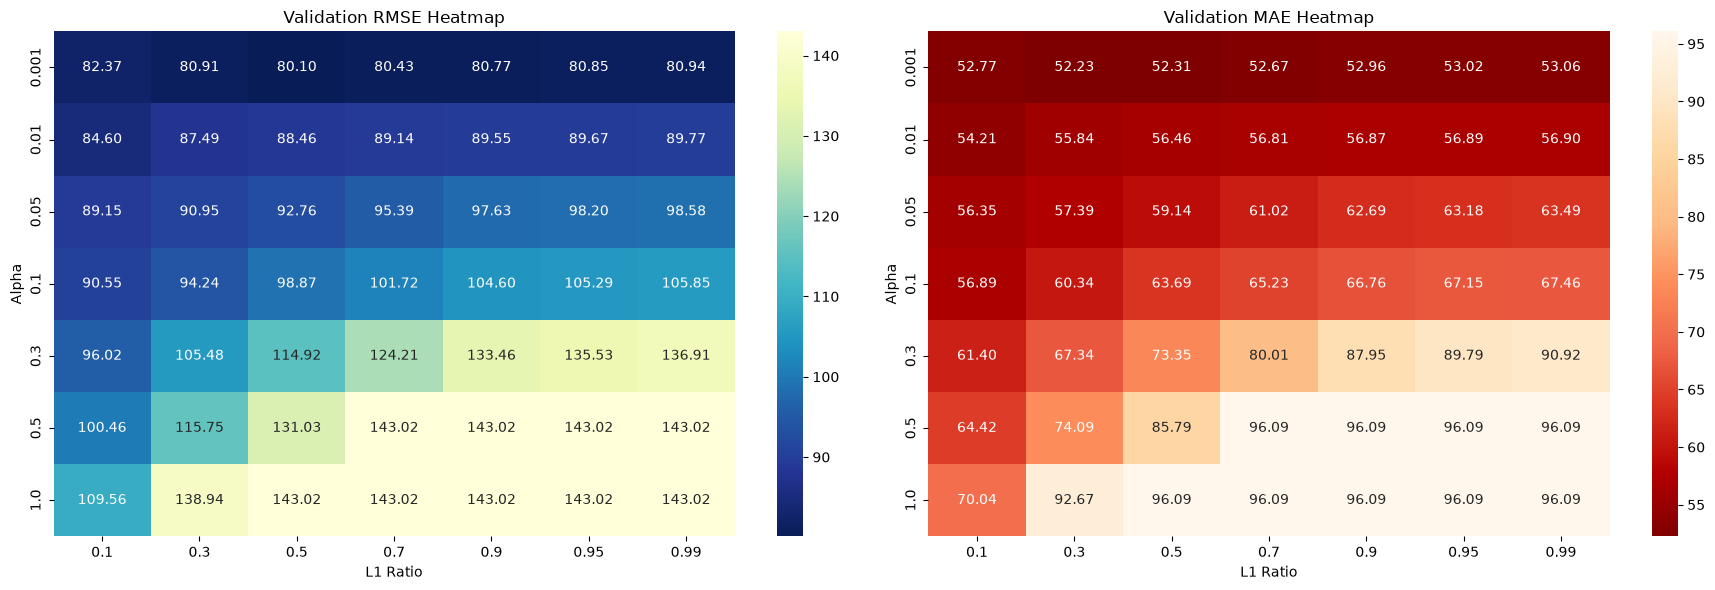

In [15]:
from sklearn.metrics import mean_absolute_error

# Define the hyperparameter grid for experimentation
alphas = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

results_with_mae = []

for alpha in alphas:
    for l1_ratio in l1_ratios:
        model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42, max_iter=10000)
        model.fit(X_train_scaled, y_train_log)

        # Predict on Validation set and convert back to original EUR scale
        y_val_pred_log = model.predict(X_val_scaled)
        y_val_pred_orig = np.expm1(y_val_pred_log)

        # Compute both RMSE and MAE
        val_rmse = np.sqrt(mean_squared_error(y_val_comb, y_val_pred_orig))
        val_mae = mean_absolute_error(y_val_comb, y_val_pred_orig)

        results_with_mae.append({
            'alpha': alpha,
            'l1_ratio': l1_ratio,
            'Validation RMSE': val_rmse,
            'Validation MAE': val_mae
        })

df_results_mae = pd.DataFrame(results_with_mae)

# Find the optimal hyperparameter set for MAE
best_mae_idx = df_results_mae['Validation MAE'].idxmin()
best_mae_param = df_results_mae.loc[best_mae_idx]

print("=== OPTIMAL HYPERPARAMETERS FOR MAE ===")
print(f"Alpha: {best_mae_param['alpha']}")
print(f"L1 Ratio: {best_mae_param['l1_ratio']}")
print(f"Lowest Validation MAE: {best_mae_param['Validation MAE']:.4f} EUR")
print(f"Corresponding Validation RMSE: {best_mae_param['Validation RMSE']:.4f} EUR")

# Plot side-by-side Heatmaps comparing Validation RMSE and Validation MAE
pivot_rmse = df_results_mae.pivot(index='alpha', columns='l1_ratio', values='Validation RMSE')
pivot_mae = df_results_mae.pivot(index='alpha', columns='l1_ratio', values='Validation MAE')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Heatmap for RMSE
sns.heatmap(pivot_rmse, annot=True, fmt=".2f", cmap="YlGnBu_r", ax=axes[0])
axes[0].set_title('Validation RMSE Heatmap')
axes[0].set_xlabel('L1 Ratio')
axes[0].set_ylabel('Alpha')

# Heatmap for MAE
sns.heatmap(pivot_mae, annot=True, fmt=".2f", cmap="OrRd_r", ax=axes[1])
axes[1].set_title('Validation MAE Heatmap')
axes[1].set_xlabel('L1 Ratio')
axes[1].set_ylabel('Alpha')

plt.tight_layout()
plt.show()

### 7. Overall Conclusions on ElasticNet Model Optimization

After performing a grid search over the hyperparameter space for ElasticNet (combining $L_1$ and $L_2$ regularization), we draw several key conclusions:

#### 1. Comparing the Two Optimization Objectives (RMSE vs. MAE)
* **Optimizing for RMSE (Root Mean Squared Error):**
  * **Best Hyperparameters:** `alpha = 0.001` and `l1_ratio = 0.5`.
  * **Result:** **Lowest Validation RMSE reaches 80.1033 EUR**.
  * *Commentary:* RMSE is highly sensitive to large errors (outliers). Setting `l1_ratio = 0.5` strikes an ideal balance between eliminating redundant features ($L_1$ - Lasso) and shrinking correlated features smoothly ($L_2$ - Ridge), preventing extreme mispredictions on ultra-expensive or ultra-cheap phones.

* **Optimizing for MAE (Mean Absolute Error):**
  * **Best Hyperparameters:** `alpha = 0.001` and `l1_ratio = 0.3`.
  * **Result:** **Lowest Validation MAE reaches 52.2349 EUR** (with a corresponding RMSE of 80.9100 EUR).
  * *Commentary:* MAE represents the average absolute error per smartphone. When optimizing for MAE, the model shifts slightly toward Ridge regularization (`l1_ratio = 0.3` — zeroing out fewer features and focusing on uniform coefficient shrinkage). As a result, the average prediction error drops to **52.23 EUR** per device (a substantial improvement over the ~58.20 EUR of the initial Baseline Linear Regression model).

#### 2. Significance of the Penalty Parameter `alpha`
* Both RMSE and MAE objectives converge to a very small penalty strength: **`alpha = 0.001`**.
* This demonstrates that our Feature Engineering pipeline (expanding from 21 to 98 features) provides highly informative signal for explaining price variation. Only a gentle regularization penalty (`alpha = 0.001`) is needed to stabilize regression weights against multicollinearity, whereas larger `alpha` values over-penalize the model and cause severe underfitting (clearly visible in the dark red/blue regions of the heatmaps).

### 8. Evaluating the Optimal ElasticNet Models on the Test Set

To ensure an objective evaluation of generalization performance on completely unseen data, we apply the two best ElasticNet configurations found during tuning to the held-out **Test Set**:

In [16]:
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Configuration 1: Optimized for RMSE (alpha=0.001, l1_ratio=0.5)
best_rmse_model = ElasticNet(
    alpha=0.001, l1_ratio=0.5, random_state=42, max_iter=10000
)
best_rmse_model.fit(X_train_scaled, y_train_log)

# Predict and invert back to original scale (EUR) for all 3 splits: Train, Val, Test
y_train_pred_rmse = np.expm1(best_rmse_model.predict(X_train_scaled))
y_val_pred_rmse = np.expm1(best_rmse_model.predict(X_val_scaled))
y_test_pred_rmse_orig = np.expm1(best_rmse_model.predict(X_test_scaled))

# 2. Configuration 2: Optimized for MAE (alpha=0.001, l1_ratio=0.3)
best_mae_model = ElasticNet(
    alpha=0.001, l1_ratio=0.3, random_state=42, max_iter=10000
)
best_mae_model.fit(X_train_scaled, y_train_log)

# Predict and invert back to original scale (EUR) for all 3 splits: Train, Val, Test
y_train_pred_mae = np.expm1(best_mae_model.predict(X_train_scaled))
y_val_pred_mae = np.expm1(best_mae_model.predict(X_val_scaled))
y_test_pred_mae_orig = np.expm1(best_mae_model.predict(X_test_scaled))


# 3. Helper function to print metrics for each split
def print_full_metrics(y_true, y_pred, dataset_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(
        f'  [{dataset_name:<10}] -> MAE: {mae:7.4f} EUR | RMSE: {rmse:7.4f} EUR | R²: {r2:.4f}'
    )


# 4. Print comprehensive Train / Validation / Test comparison to check for Overfitting
print(
    '================ COMPREHENSIVE EVALUATION (TRAIN vs VAL vs TEST) ================'
)

print('\n--- 1. RMSE-OPTIMIZED CONFIGURATION (alpha=0.001, l1_ratio=0.5) ---')
print_full_metrics(y_train_comb, y_train_pred_rmse, 'TRAIN')
print_full_metrics(y_val_comb, y_val_pred_rmse, 'VALIDATION')
print_full_metrics(y_test_comb, y_test_pred_rmse_orig, 'TEST')

print('\n--- 2. MAE-OPTIMIZED CONFIGURATION (alpha=0.001, l1_ratio=0.3) ---')
print_full_metrics(y_train_comb, y_train_pred_mae, 'TRAIN')
print_full_metrics(y_val_comb, y_val_pred_mae, 'VALIDATION')
print_full_metrics(y_test_comb, y_test_pred_mae_orig, 'TEST')

================ COMPREHENSIVE EVALUATION (TRAIN vs VAL vs TEST) ================

--- 1. RMSE-OPTIMIZED CONFIGURATION (alpha=0.001, l1_ratio=0.5) ---
  [TRAIN     ] -> MAE: 48.4169 EUR | RMSE: 73.8802 EUR | R²: 0.7088
  [VALIDATION] -> MAE: 52.3145 EUR | RMSE: 80.1033 EUR | R²: 0.6681
  [TEST      ] -> MAE: 51.1209 EUR | RMSE: 77.6483 EUR | R²: 0.6588

--- 2. MAE-OPTIMIZED CONFIGURATION (alpha=0.001, l1_ratio=0.3) ---
  [TRAIN     ] -> MAE: 47.7533 EUR | RMSE: 72.6767 EUR | R²: 0.7182
  [VALIDATION] -> MAE: 52.2349 EUR | RMSE: 80.9100 EUR | R²: 0.6614
  [TEST      ] -> MAE: 50.6253 EUR | RMSE: 76.1167 EUR | R²: 0.6721


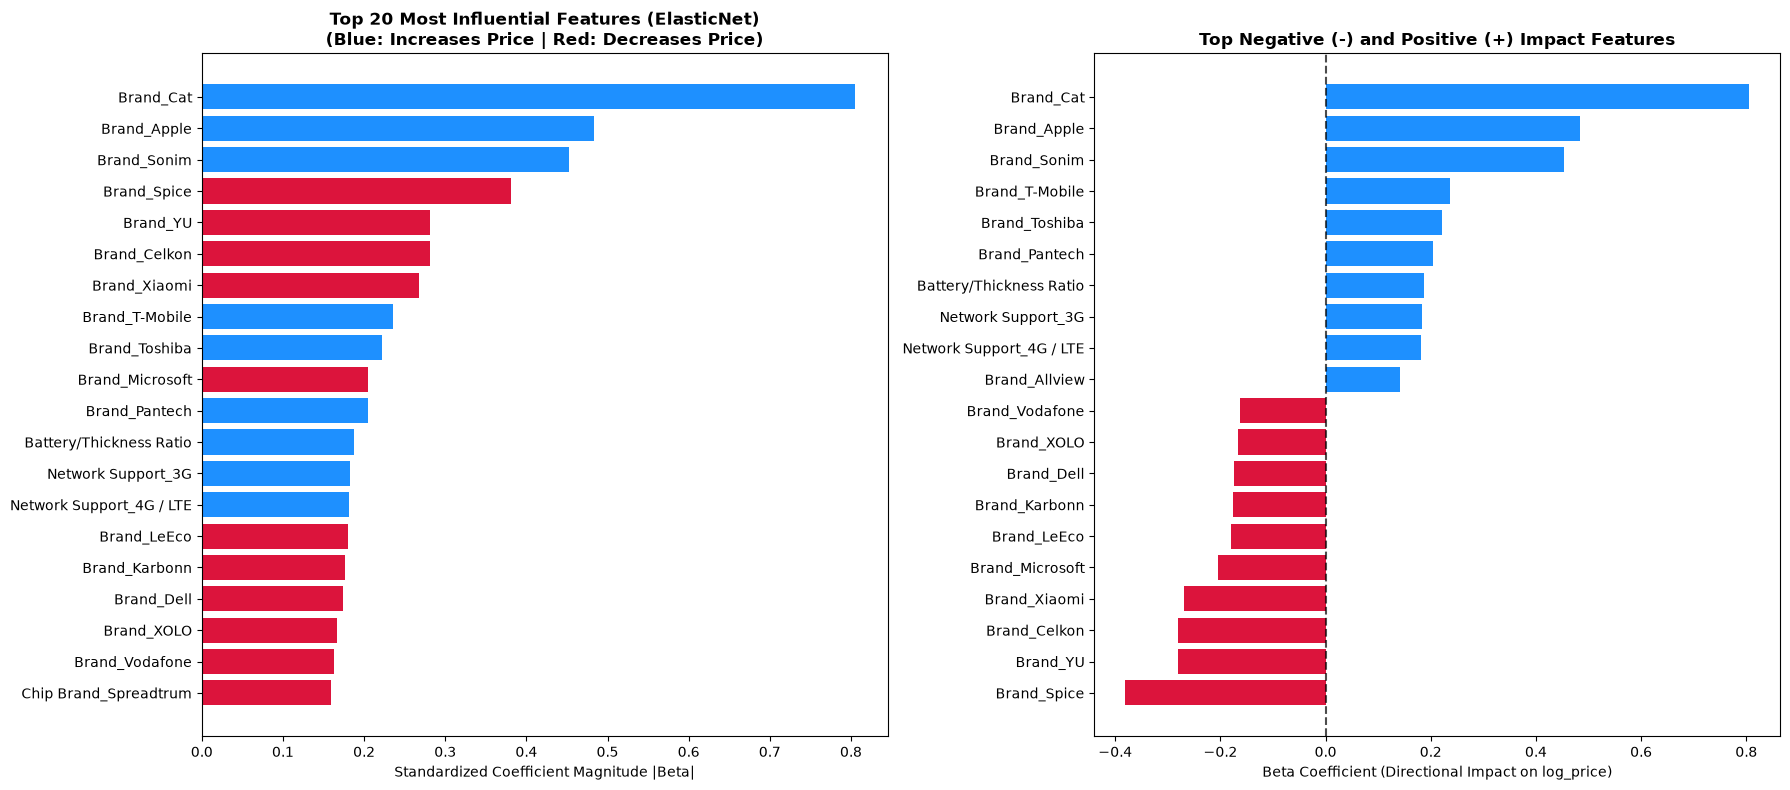

=== TOP 15 FEATURES WITH LARGEST WEIGHTS IN ELASTICNET ===


,Feature,Coefficient (Beta),Importance (|Beta|)
0,Brand_Cat,0.804800,0.804800
1,Brand_Apple,0.483727,0.483727
2,Brand_Sonim,0.452655,0.452655
3,Brand_Spice,-0.380452,0.380452
4,Brand_YU,-0.281316,0.281316
5,Brand_Celkon,-0.280678,0.280678
6,Brand_Xiaomi,-0.268272,0.268272
7,Brand_T-Mobile,0.236009,0.236009
8,Brand_Toshiba,0.221663,0.221663
9,Brand_Microsoft,-0.204535,0.204535


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Explain the optimal ElasticNet model: best_rmse_model
model_to_explain = best_rmse_model
feature_names = X_train_scaled.columns

# 1. Extract regression coefficients (Beta)
coef_df = pd.DataFrame(
    {'Feature': feature_names, 'Coefficient (Beta)': model_to_explain.coef_}
)

# Compute absolute magnitude to rank feature importance
coef_df['Importance (|Beta|)'] = coef_df['Coefficient (Beta)'].abs()
coef_df = coef_df.sort_values(by='Importance (|Beta|)', ascending=False)

# 2. Plot 2 charts:
#    - Chart 1: Top 20 most influential features (by absolute magnitude)
#    - Chart 2: Directional impact (Top 10 positive vs Top 10 negative price drivers)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

# Subplot 1: Top 20 absolute magnitude
top_20 = coef_df.head(20).sort_values(by='Importance (|Beta|)', ascending=True)
colors = ['crimson' if c < 0 else 'dodgerblue' for c in top_20['Coefficient (Beta)']]

axes[0].barh(top_20['Feature'], top_20['Importance (|Beta|)'], color=colors)
axes[0].set_title(
    'Top 20 Most Influential Features (ElasticNet)\n(Blue: Increases Price | Red: Decreases Price)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Standardized Coefficient Magnitude |Beta|')

# Subplot 2: Top 10 positive and Top 10 negative features
top_pos = (
    coef_df.sort_values(by='Coefficient (Beta)', ascending=False)
    .head(10)
    .sort_values(by='Coefficient (Beta)', ascending=True)
)
top_neg = coef_df.sort_values(by='Coefficient (Beta)', ascending=True).head(10)
signed_df = pd.concat([top_neg, top_pos])
signed_colors = [
    'crimson' if c < 0 else 'dodgerblue' for c in signed_df['Coefficient (Beta)']
]

axes[1].barh(signed_df['Feature'], signed_df['Coefficient (Beta)'], color=signed_colors)
axes[1].axvline(x=0, color='black', linestyle='--', alpha=0.7)
axes[1].set_title(
    'Top Negative (-) and Positive (+) Impact Features',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Beta Coefficient (Directional Impact on log_price)')

plt.tight_layout()
plt.show()

# Print Top 15 table for reporting
print('=== TOP 15 FEATURES WITH LARGEST WEIGHTS IN ELASTICNET ===')
display(
    coef_df[
        ['Feature', 'Coefficient (Beta)', 'Importance (|Beta|)']
    ].reset_index(drop=True).head(15)
)